### Analysis of wildlife data in Great Britain and Northern Ireland

## Data

The data is collected from NBN Atlas<sup>1</sup>, using citizen science observations uploaded to iNaturalist<sup>2</sup>. This source was used as it provides the most comprehensive and in depth biodiversity and wildlife data for Great Britain and Northern Ireland<sup>3</sup>. 

The dataset includes:

 - Species
 - Location

In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

/Users/oisinlarkinjones/Documents/LIS/Y3/ds2026/.venv/lib/python3.14/site-packages/pyogrio/raw.py:200: RuntimeWarning: Non-conformant content for record 1 in column DESIG_DATE, 2006-04-01T00:00:00.0Z, successfully parsed
  return ogr_read(


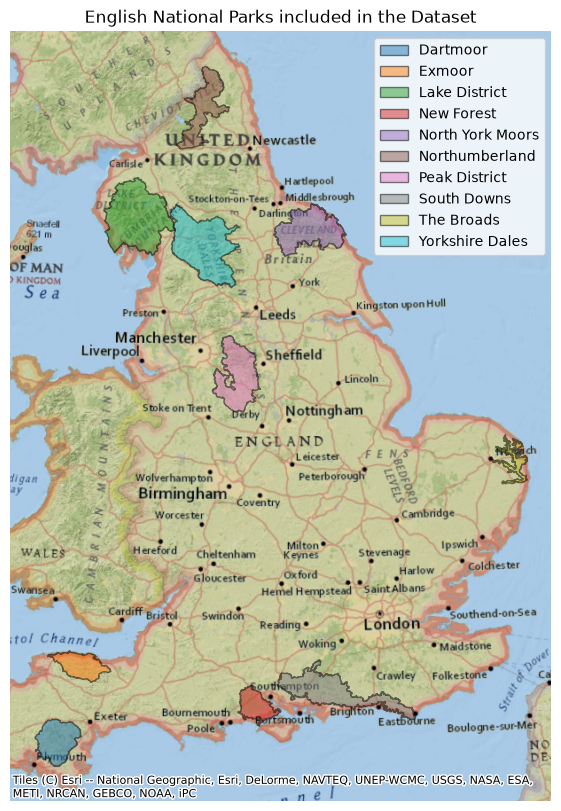

In [2]:
national_parks = gpd.read_file('data/National_Parks_England_6904927081194970581.gpkg')

def tidy_text(s):
    return s.astype('string').str.strip().str.title()

national_parks['NAME'] = tidy_text(national_parks['NAME'])

ax = national_parks.plot(tiles="Esri.NatGeoWorldMap",
                         edgecolor='black',
                         alpha=0.5,
                         figsize=(10,10),
                         column='NAME',
                         categorical=True,
                         legend=True,
                         legend_kwds={'loc':'upper right'},)
ax.set_title('English National Parks included in the Dataset')
ax.set_axis_off()


In [3]:
dartmoor = pd.read_csv('data/Dartmoor/records-2026-10-13.csv')

/var/folders/7w/8tb_8k716vg8b2rbds3zfq980000gn/T/ipykernel_13929/1379514293.py:1: DtypeWarning: Columns (27: Organism scope, 28: Organism remarks) have mixed types. Specify dtype option on import or set low_memory=False.
  dartmoor = pd.read_csv('data/Dartmoor/records-2026-10-13.csv')


In [ ]:
columns = dartmoor.columns.tolist()

c_name = dartmoor['Common name']


dartmoor['Common name'] = tidy_text(dartmoor['Common name'])
counts = dartmoor['Common name'].value_counts()
dartmoor['Abundance'] = dartmoor['Common name'].map(counts)
dartmoor = dartmoor.drop_duplicates('Common name')
dartmoor['Abundance'].describe()

count        5235.0
mean     183.654059
std        716.9539
min             1.0
25%             2.0
50%            11.0
75%            82.0
max         14118.0
Name: Abundance, dtype: Float64

In [21]:
dartmoor.columns

Index(['NBN Atlas record ID', 'Occurrence ID', 'Licence', 'rightsHolder',
       'Scientific name', 'Taxon author', 'Name qualifier', 'Common name',
       'Species ID (TVK)', 'Taxon Rank', 'Occurrence status', 'Event Date',
       'Day', 'Month', 'Year', 'End date', 'Locality', 'Grid reference',
       'Latitude (WGS84)', 'Longitude (WGS84)', 'Coordinate Uncertainty (m)',
       'verbatimDepth', 'Recorder', 'Determiner', 'Individual count',
       'Abundance', 'Abundance scale', 'Organism scope', 'Organism remarks',
       'Sex', 'Life stage', 'Occurrence remarks',
       'Identification verification status', 'Basis of Record', 'Survey key',
       'Dataset name', 'Dataset ID', 'Data provider', 'Data provider ID',
       'Institution code', 'Kingdom', 'Phylum', 'Class', 'Order', 'Family',
       'Genus', 'OSGR 100km', 'OSGR 10km', 'OSGR 2km', 'OSGR 1km', 'Country',
       'State/Province', 'Vitality', 'Public resolution (m)2',
       'Sensitive status', 'Generalised status'],
      dt

,Day,Month,Year,Latitude (WGS84),Longitude (WGS84),Coordinate Uncertainty (m),verbatimDepth,Individual count,Abundance,Public resolution (m)2
count,615.000000,628.000000,633.000000,633.000000,633.000000,630.000000,0.0,541.000000,633.0,0.0
mean,15.564228,6.632166,2009.519747,51.896033,-3.350952,1223.030476,NaN,2.064695,208.099526,NaN
std,9.129115,1.884221,14.823113,0.059688,0.231951,920.187115,NaN,4.246292,386.85847,NaN
min,1.000000,1.000000,1900.000000,51.751820,-3.962297,4.000000,NaN,1.000000,1.0,NaN
25%,8.000000,6.000000,2007.000000,51.854637,-3.511003,1414.200000,NaN,1.000000,6.0,NaN
50%,16.000000,7.000000,2013.000000,51.914699,-3.266842,1414.200000,NaN,1.000000,44.0,NaN
75%,23.000000,8.000000,2018.000000,51.934683,-3.178650,1414.200000,NaN,2.000000,254.0,NaN
max,31.000000,12.000000,2026.000000,52.075818,-2.972760,7071.100000,NaN,57.000000,3307.0,NaN


In [6]:
dartmoor_points = gpd.GeoDataFrame(
    dartmoor,
    geometry=gpd.points_from_xy(
        dartmoor['Longitude (WGS84)'],  # TODO: longitude column
        dartmoor['Latitude (WGS84)']   # TODO: latitude column
    ),
    crs="EPSG:4326"
)

dartmoor_points.plot(ax=ax, color=('black'))

plt.show()